In [44]:
import pandas as pd
import numpy as np
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st
import joblib


In [45]:
df = pd.read_csv(r"preprocessed_data_outliers_not_removed.csv")

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ["area", "bhk", "bathroom", "age"]
categorical_features = ["status", "location", "builder"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

#Split Data
X = df.drop("price", axis=1)
Y = df["price"]


In [47]:
# MODEL BUILDING
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Lasso())
])

param_grid = {
    'regressor__alpha': np.logspace(-3, 0, 10)
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error'
)

grid_search.fit(X_train, Y_train)

lasso = grid_search.best_estimator_




In [57]:
from sklearn.metrics import mean_squared_error, r2_score

Y_pred_test = lasso.predict(X_test)
Y_pred_train = lasso.predict(X_train)

mse = mean_squared_error(Y_test, Y_pred_test)
rmse = np.sqrt(mse)
r2_test = r2_score(Y_test, Y_pred_test)
r2_train = r2_score(Y_train, Y_pred_train)
print("MSE:", mse)
print("RMSE:", rmse)
print("R^2 Test:", r2_test)
print("R^2 Train", r2_train)

MSE: 710.7984631110776
RMSE: 26.660803872184303
R^2 Test: 0.9466433527236622
R^2 Train 0.9448356975965606


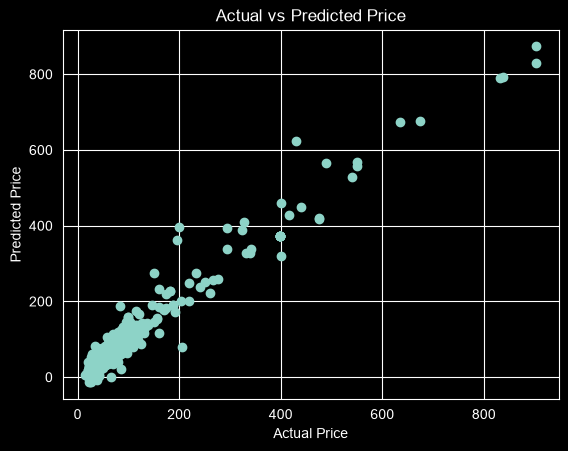

In [58]:
# VISUALIZATION
plt.scatter(Y_test, Y_pred_test)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.show()

In [65]:
#Lasso Model
new_house = pd.DataFrame({
    "area": [650],
    "bhk": [1],
    "bathroom": [1],
    "age": [1],
    "status": ["ready"],
    "location": ["Perungalathur"],
    "builder": ["DAC Promoters"]
})

prediction = lasso.predict(new_house)

price_lakh = prediction[0]
if price_lakh < 1:
    print(f"Predicted Price: ₹{price_lakh * 100000:,.0f}")
elif price_lakh < 100:
    print(f"Predicted Price: ₹{price_lakh:,.2f} lakh")
elif price_lakh < 100000:
    print(f"Predicted Price: ₹{price_lakh / 100:,.2f} crore")
else:
    print(f"Predicted Price: ₹{price_lakh / 100000:,.2f} thousand crore")

Predicted Price: ₹49.67 lakh


In [52]:
joblib.dump(lasso, "house_price_Lassomodel.pkl")

['house_price_Lassomodel.pkl']

# FINAL REPORT
The Lasso Regression model achieved an MSE of 710.80 and an RMSE of 26.66 on the test set. The model obtained an R² score of 0.9466 on the testing data and 0.9448 on the training data, indicating that approximately 94.66% of the variance in house prices is explained by the selected features. The small difference between the training and testing R² scores demonstrates strong generalization capability and minimal overfitting. Furthermore, the model slightly outperformed the Linear Regression model by achieving a lower RMSE and a higher test R² score. These results indicate that the Lasso Regression model is robust, reliable, and well-suited for predicting house prices in the Chennai housing dataset.

In [59]:
df1 = pd.read_csv(r"preprocessed_data_outliers_removed.csv")

In [60]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ["area", "bhk", "bathroom", "age"]
categorical_features = ["status", "location", "builder"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

#Split Data
X1 = df1.drop("price", axis=1)
Y1 = df1["price"]


In [61]:
# MODEL BUILDING
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split

X1_train, X1_test, Y1_train, Y1_test = train_test_split(X1, Y1, test_size=0.2, random_state=42)

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Lasso())
])

param_grid = {
    'regressor__alpha': np.logspace(-3, 0, 10)
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error'
)

grid_search.fit(X1_train, Y1_train)

lasso_adjusted_to_outlier = grid_search.best_estimator_

In [62]:
from sklearn.metrics import mean_squared_error, r2_score

Y1_pred_test = lasso_adjusted_to_outlier.predict(X1_test)
Y1_pred_train = lasso_adjusted_to_outlier.predict(X1_train)

mse = mean_squared_error(Y1_test, Y1_pred_test)
rmse = np.sqrt(mse)
r2_test = r2_score(Y1_test, Y1_pred_test)
r2_train = r2_score(Y1_train, Y1_pred_train)
print("MSE:", mse)
print("RMSE:", rmse)
print("R^2 Test:", r2_test)
print("R^2 Train", r2_train)

MSE: 144.2212963527382
RMSE: 12.009217141543331
R^2 Test: 0.9311786123395833
R^2 Train 0.9499659434405625


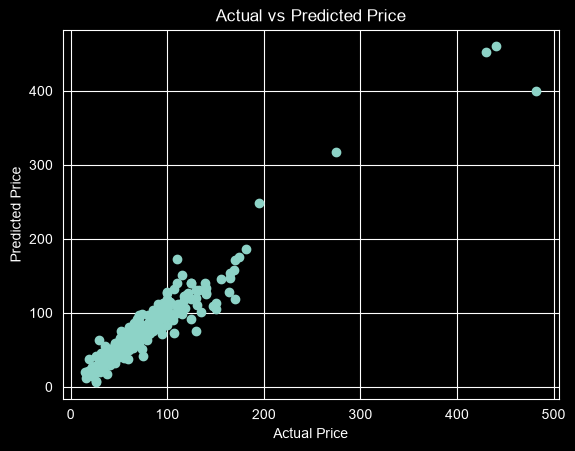

In [63]:
# VISUALIZATION
plt.scatter(Y1_test, Y1_pred_test)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.show()

In [66]:
#Lasso Model
new_house = pd.DataFrame({
    "area": [650],
    "bhk": [1],
    "bathroom": [1],
    "age": [1],
    "status": ["ready"],
    "location": ["Perungalathur"],
    "builder": ["DAC Promoters"]
})

prediction = lasso_adjusted_to_outlier.predict(new_house)

price_lakh = prediction[0]
if price_lakh < 1:
    print(f"Predicted Price: ₹{price_lakh * 100000:,.0f}")
elif price_lakh < 100:
    print(f"Predicted Price: ₹{price_lakh:,.2f} lakh")
elif price_lakh < 100000:
    print(f"Predicted Price: ₹{price_lakh / 100:,.2f} crore")
else:
    print(f"Predicted Price: ₹{price_lakh / 100000:,.2f} thousand crore")
print(prediction)

Predicted Price: ₹50.41 lakh
[50.40516034]


In [ ]:
joblib.dump(lasso, "lasso_adjusted_to_outlier_model.pkl")